In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Plot-only notebook: the numbers are produced by `python postprocess.py` (-> ./data/*.csv)
os.makedirs('../plots', exist_ok=True)

In [2]:
df = pd.read_csv('data/zero_noise_graph.csv')

In [3]:
modelTraces = ['10', '20', '30', '40', '50', '70', '150']

In [4]:
layers = ['conv1', 'conv2', 'conv3', 'conv4', 'conv5', 'conv6', 'fc1', 'fc2']
err = df.set_index(['leakage', 'traces_k', 'layer'])['error_prob']
layersDict_per_leak_mod = {leak_mod: {layer: [err[leak_mod, int(t), layer] for t in modelTraces] for layer in layers}
                           for leak_mod in ['HD', 'HW']}

In [5]:
layersDict_per_leak_mod_per_trace = {leak_mod: {f'{t}k': [err[leak_mod, int(t), layer] for layer in layers] for t in modelTraces}
                                     for leak_mod in ['HD', 'HW']}

In [6]:
legend = [f'{modelTrace}k' for modelTrace in modelTraces]

In [7]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_misextraction_sns(layers, layersDict, legend, trace_nums,
                           figsize=(16, 8),
                           font_size=32,      # <--- one control for ALL fonts
                           base_jitter=0.2, max_jitter=0.5,
                           leak_model = 'HD'):
    """
    layers: list of layer names (in order)
    layersDict: dict mapping layer -> list of mis-extraction probabilities
    legend: labels for different trace counts (e.g. ["10k","20k",...])
    trace_nums: numeric trace counts (e.g. [10000,20000,...])
    """

    # GLOBAL FONT SIZE CONTROL
    sns.set(style="whitegrid")
    sns.set_context("notebook")

    # -----------------------------------
    # Marker sizes
    # -----------------------------------
    min_size, max_size = 300, 1000
    trace_nums = np.asarray(trace_nums, dtype=float)
    size_norm = (trace_nums - trace_nums.min()) / (trace_nums.max() - trace_nums.min())
    sizes = [min_size + size_norm[i] * (max_size - min_size) for i in range(len(legend))]

    # -----------------------------------
    # Colors for each trace (stable)
    # -----------------------------------
    colors = (
        list(plt.get_cmap('tab20').colors) +
        list(plt.get_cmap('tab20b').colors) +
        list(plt.get_cmap('tab20c').colors)
    )[::2]

    # -----------------------------------
    # Build dataframe
    # -----------------------------------
    rows = []
    for layer in layers:
        for i, value in enumerate(layersDict[layer]):
            rows.append((layer, value, legend[i]))

    df = pd.DataFrame(rows, columns=["layer", "prob", ""])

    # -----------------------------------
    # X numeric + jitter
    # -----------------------------------
    layer_to_x = {layer: idx for idx, layer in enumerate(layers)}
    df["x"] = df["layer"].map(layer_to_x)

    rng = np.random.default_rng(0)
    jitter_list = []

    for layer in layers:
        y = np.asarray(layersDict[layer], dtype=float)
        unique_vals, counts = np.unique(y, return_counts=True)
        count_map = dict(zip(unique_vals, counts))

        for yi in y:
            c = count_map[yi]
            if c > 1:
                scale = min(base_jitter * (c - 1), max_jitter)
                jitter_list.append(rng.uniform(-scale, scale))
            else:
                jitter_list.append(0.0)

    df["x_jitter"] = df["x"] + np.asarray(jitter_list)

    # -----------------------------------
    # Size & color mapping
    # -----------------------------------
    size_map = {legend[i]: sizes[i] for i in range(len(legend))}
    color_map = {legend[i]: colors[i] for i in range(len(legend))}

    # -----------------------------------
    # Plot
    # -----------------------------------
    fig, ax = plt.subplots(figsize=figsize)

    sns.scatterplot(
        data=df,
        x="x_jitter",
        y="prob",
        hue="",
        palette=color_map,
        size="",
        sizes=size_map,
        ax=ax,
        marker="X",
        legend=True
    )

    # -----------------------------------
    # Axis formatting
    # -----------------------------------
    ax.set_yscale("symlog", linthresh=1e-4, linscale=1.0)

    # *** Force y-limits to start at 0 ***
    ax.set_ylim(bottom=-0.00001)

    ax.set_xticks(range(len(layers)))
    
    ax.set_xticklabels(layers, rotation=-45, ha="center", fontsize=font_size)

    ax.set_xlabel("Network Layer", fontsize=font_size)
    ax.set_ylabel("Mis-extraction Probability", fontsize=font_size)
    ax.tick_params(axis="y", labelsize=font_size)

    # Stronger frame
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

    ax.grid(True, which="both", linestyle="--", linewidth=0.7)
    ax.legend(title=None, fontsize=font_size-9, framealpha=0.95)

    plt.tight_layout()
    plt.savefig(f"../plots/extraction_err_probs_{leak_model}.pdf",
            format="pdf",
            bbox_inches="tight",
            metadata={"Creator": "Matplotlib"})
    plt.show()

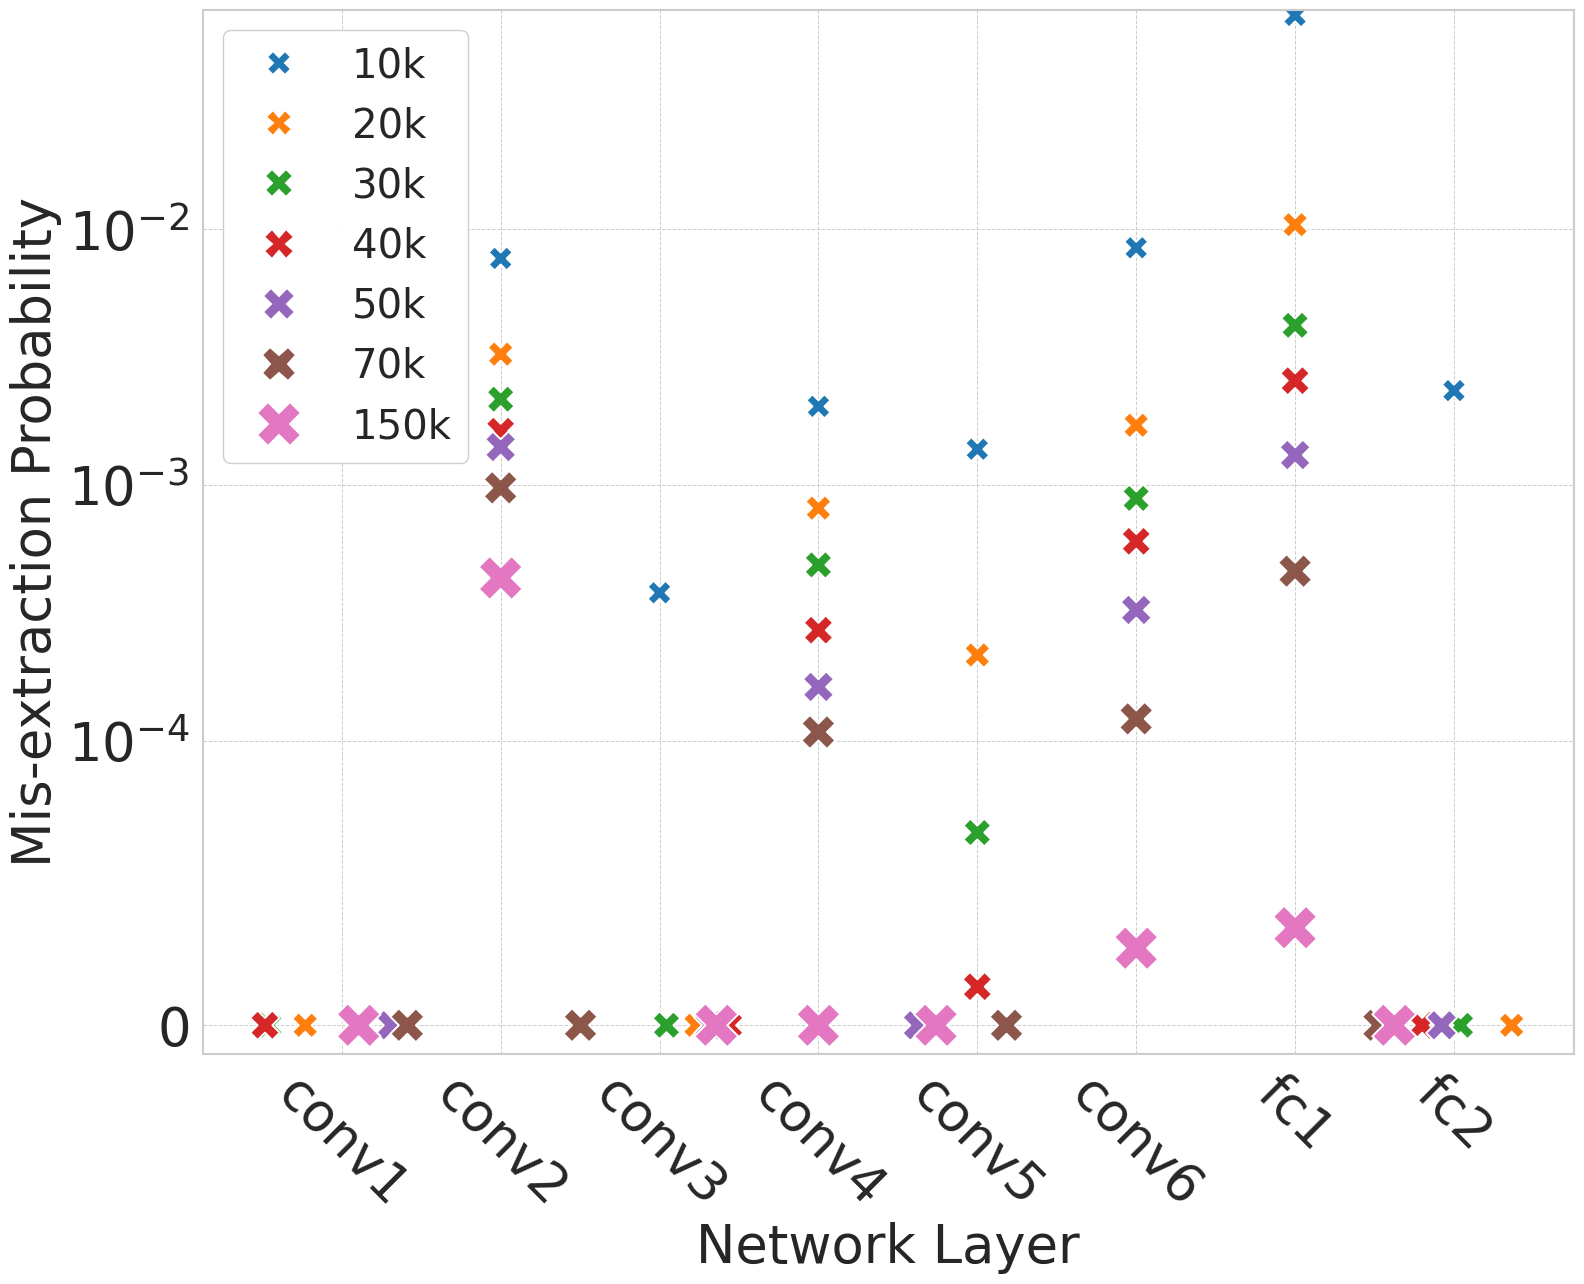

In [8]:
plot_misextraction_sns(
    layers=layers,
    layersDict=layersDict_per_leak_mod['HD'],
    legend=legend,
    trace_nums=modelTraces,
    figsize=(16, 13),
    font_size=38,
    leak_model = 'HD'
)


In [9]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

def plot_misextraction_traces_dict(
    layers,
    traces_dict,                 # dict: "10k"->list length len(layers)
    figsize=(16, 8),
    font_size=24,
    marker_size=10,
    yscale="symlog",
    linthresh=1e-4,
    linscale=1.0,
    eps=1e-8,
    xlabel="Number of Traces",
    ylabel="Error Probability",
    title="",
    linewidth=3,
    savepath="../plots/extraction_err_probs_by_traces.pdf",
):
    """
    Legend order is sorted by the OVERALL AVERAGE (mean) of each line's y-values.
    Higher average -> appears first in legend.
    """
    sns.set(style="whitegrid")

    # ---- sort trace keys numerically (e.g., "10k" < "70k" < "150k") ----
    def trace_key(t):
        s = str(t).strip().lower().replace(",", "")
        if s.endswith("k"):
            return float(s[:-1])
        return float(s)

    trace_labels = sorted(list(traces_dict.keys()), key=trace_key)
    n_layers = len(layers)

    # ---- build long dataframe: (trace, layer, prob) ----
    rows = []
    for tr in trace_labels:
        vals = np.asarray(traces_dict[tr], dtype=float)
        if vals.shape[0] != n_layers:
            raise ValueError(f"Trace '{tr}' has {vals.shape[0]} values, expected {n_layers} (len(layers))")
        for li, layer in enumerate(layers):
            rows.append((tr, layer, float(vals[li]) + eps))

    df = pd.DataFrame(rows, columns=["trace", "layer", "prob"])

    # ---- x numeric positions (display original labels) ----
    trace_to_x = {tr: i for i, tr in enumerate(trace_labels)}
    df["x"] = df["trace"].map(trace_to_x).astype(float)

    # ---- figure ----
    fig, ax = plt.subplots(figsize=figsize)

    # unique marker per layer
    marker_cycle = ["o", "s", "^", "D", "v", "P", "X", "*", "<", ">", "h", "H", "p", "8", "+", "x"]
    layer_to_marker = {layer: marker_cycle[i % len(marker_cycle)] for i, layer in enumerate(layers)}

    # plot one layer at a time
    for layer in layers:
        sub = df[df["layer"] == layer].sort_values("x")
        ax.plot(
            sub["x"].to_numpy(),
            sub["prob"].to_numpy(),
            marker=layer_to_marker[layer],
            linewidth=linewidth,
            markersize=marker_size,
            label=layer
        )

    # ---- y scale ----
    if yscale == "symlog":
        ax.set_yscale("symlog", linthresh=linthresh, linscale=linscale)
    elif yscale is not None:
        ax.set_yscale(yscale)

    # ---- labels & ticks ----
    ax.set_xlabel(xlabel, fontsize=font_size)
    ax.set_ylabel(ylabel, fontsize=font_size)
    if title:
        ax.set_title(title, fontsize=font_size)

    ax.set_xticks(range(len(trace_labels)))
    ax.set_xticklabels(trace_labels, rotation=-45, ha="center", fontsize=font_size)
    ax.tick_params(axis="y", labelsize=font_size)

    ax.grid(True, which="both", linestyle="--", linewidth=0.7)
    ax.set_ylim(bottom=-1e-6, top=1)

    # ---- legend order by overall mean of y-values ----
    handles, lbls = ax.get_legend_handles_labels()

    ranked = []
    for h, lab in zip(handles, lbls):
        if hasattr(h, "get_ydata"):
            y = np.asarray(h.get_ydata(), dtype=float)
            if y.size:
                score = float(np.nanmean(y))   # <-- overall average metric
                ranked.append((score, h, lab))

    ranked.sort(key=lambda t: t[0], reverse=True)  # highest mean first
    ordered_handles = [h for _, h, _ in ranked]
    ordered_labels  = [lab for _, _, lab in ranked]

    ax.legend(ordered_handles, ordered_labels, fontsize=font_size, framealpha=0.95, ncol=2)

    plt.tight_layout()
    plt.savefig(savepath, format="pdf", bbox_inches="tight", metadata={"Creator": "Matplotlib"})
    plt.show()
    

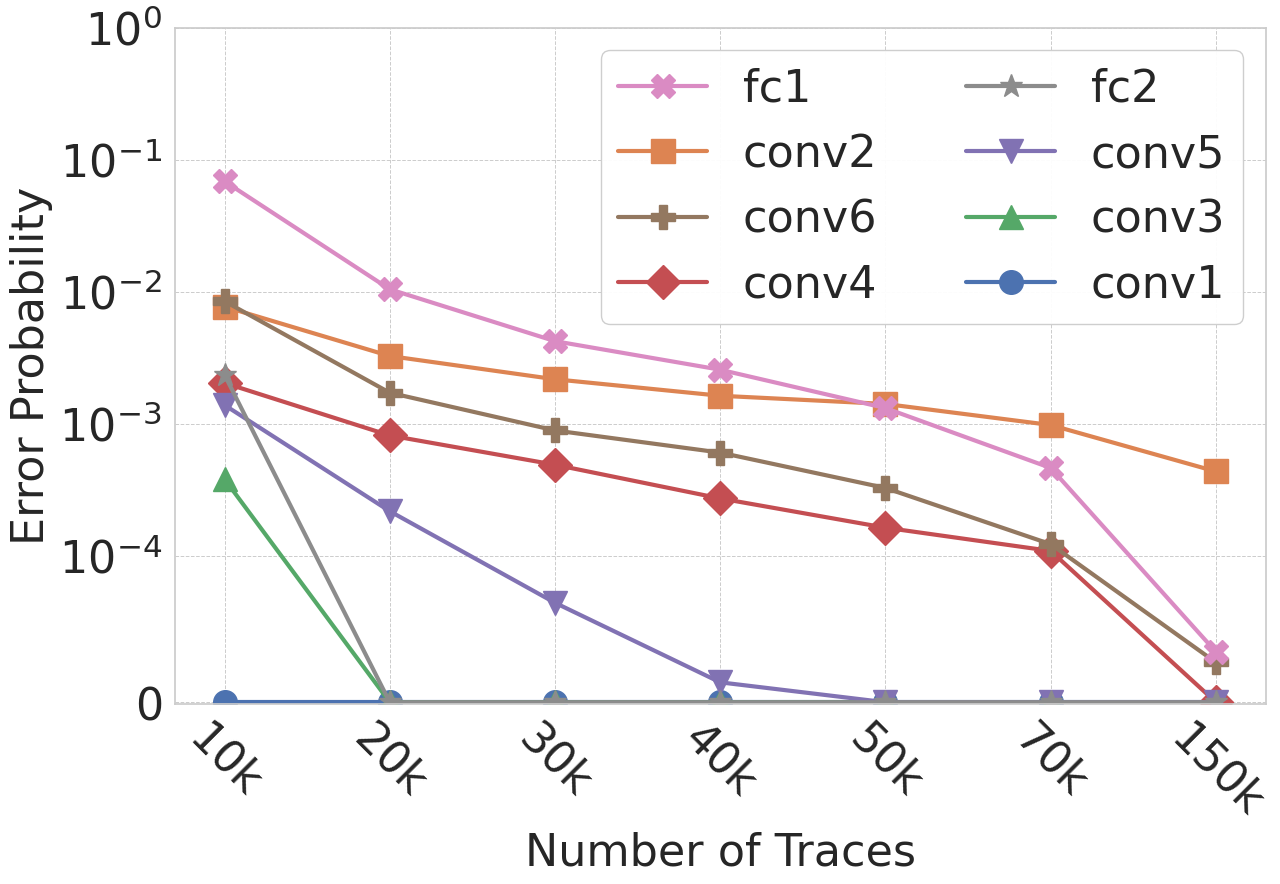

In [10]:
layers = ["conv1","conv2","conv3","conv4","conv5","conv6","fc1","fc2"]
plot_misextraction_traces_dict(
    layers=layers,
    traces_dict=layersDict_per_leak_mod_per_trace["HD"],   # if it's dict: "10k"->list per layer
    savepath="../plots/misextraction_HD_traces_xaxis.pdf",
    figsize=(13, 9),
    font_size=32,                # <-- use absolute font size (not font_scale)
    marker_size=17,
    
)

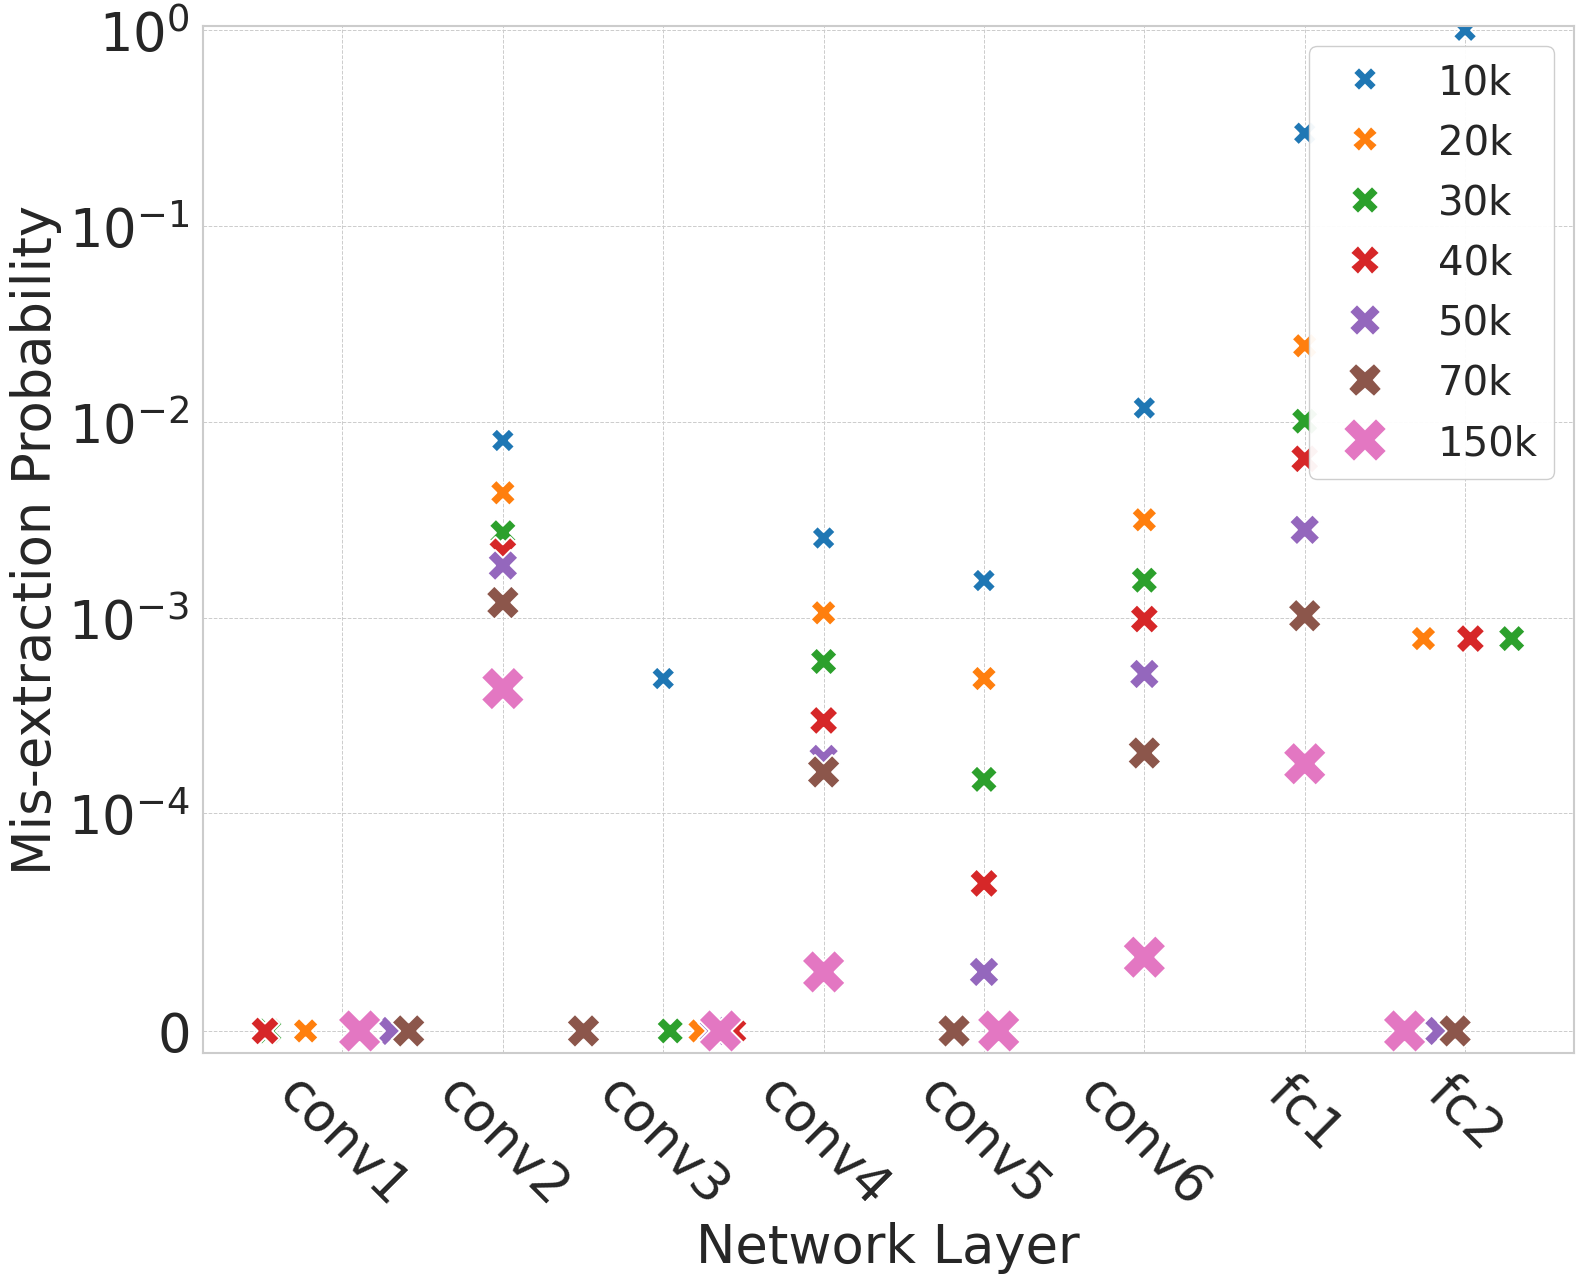

In [11]:
plot_misextraction_sns(
    layers=layers,
    layersDict=layersDict_per_leak_mod['HW'],
    legend=legend,
    trace_nums=modelTraces,
    figsize=(16, 13),
    font_size=38,
    leak_model = 'HW'
)


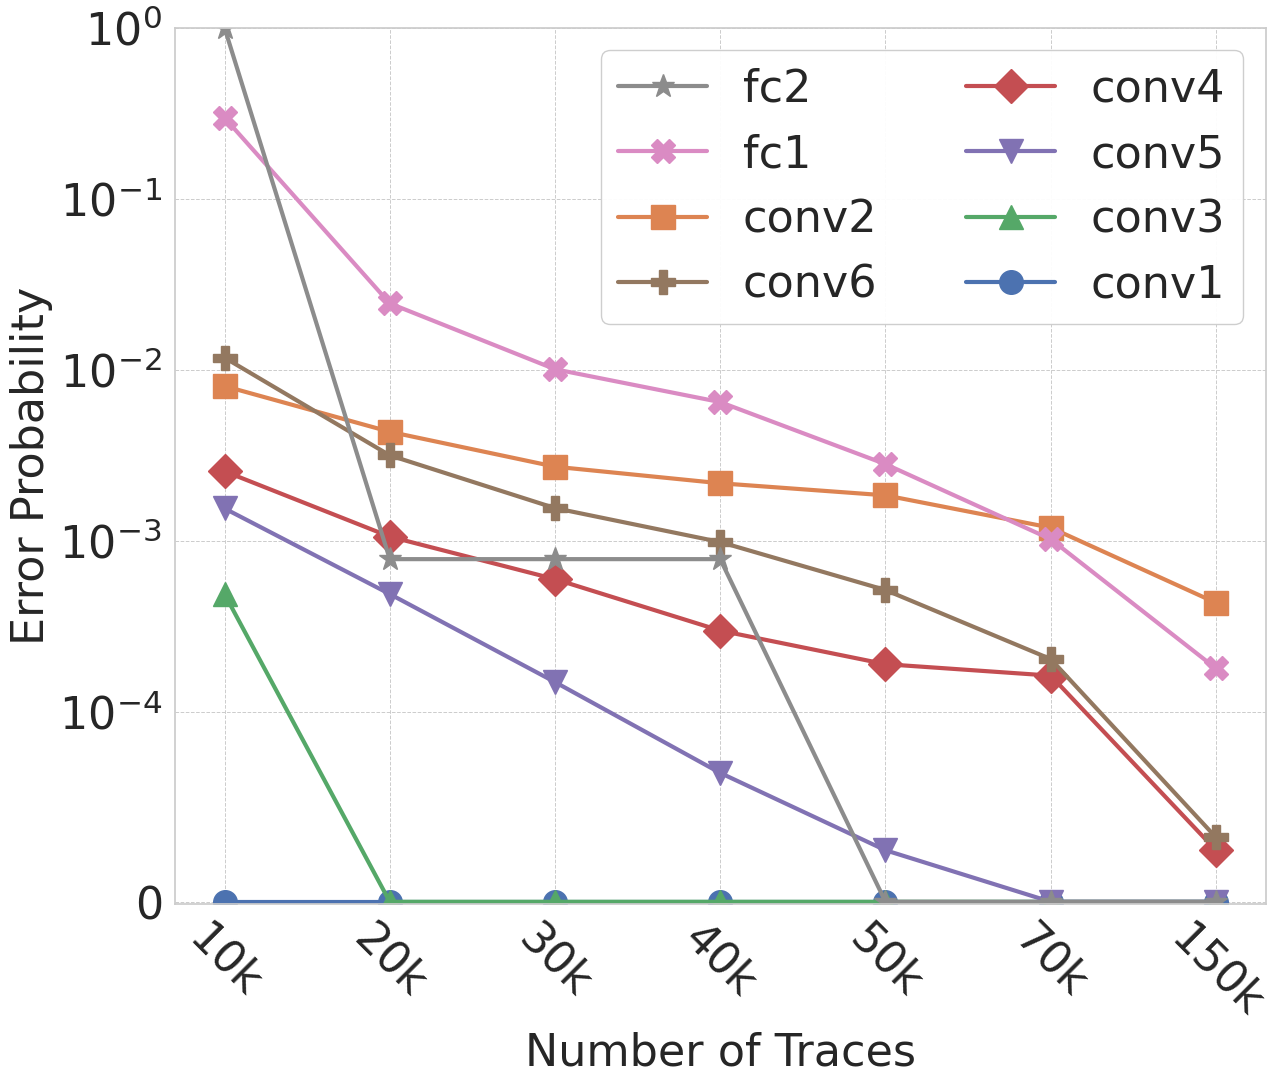

In [12]:
layers = ["conv1","conv2","conv3","conv4","conv5","conv6","fc1","fc2"]
plot_misextraction_traces_dict(
    layers=layers,
    traces_dict=layersDict_per_leak_mod_per_trace["HW"],   # if it's dict: "10k"->list per layer
    savepath="../plots/misextraction_HW_traces_xaxis.pdf",
    figsize=(13, 11),
    font_size=32,                # <-- use absolute font size (not font_scale)
    marker_size=17,
    
)